In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

In [4]:
uploaded = files.upload()

filename = next(iter(uploaded))
print('Загружен файл:', filename)

# Читаем в DataFrame
df = pd.read_csv(filename)
print(f'Размер датасета: {df.shape}')
df.head()

Saving creditcard_2023.csv to creditcard_2023.csv
Загружен файл: creditcard_2023.csv
Размер датасета: (568630, 31)


,id,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568630 entries, 0 to 568629
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      568630 non-null  int64  
 1   V1      568630 non-null  float64
 2   V2      568630 non-null  float64
 3   V3      568630 non-null  float64
 4   V4      568630 non-null  float64
 5   V5      568630 non-null  float64
 6   V6      568630 non-null  float64
 7   V7      568630 non-null  float64
 8   V8      568630 non-null  float64
 9   V9      568630 non-null  float64
 10  V10     568630 non-null  float64
 11  V11     568630 non-null  float64
 12  V12     568630 non-null  float64
 13  V13     568630 non-null  float64
 14  V14     568630 non-null  float64
 15  V15     568630 non-null  float64
 16  V16     568630 non-null  float64
 17  V17     568630 non-null  float64
 18  V18     568630 non-null  float64
 19  V19     568630 non-null  float64
 20  V20     568630 non-null  f

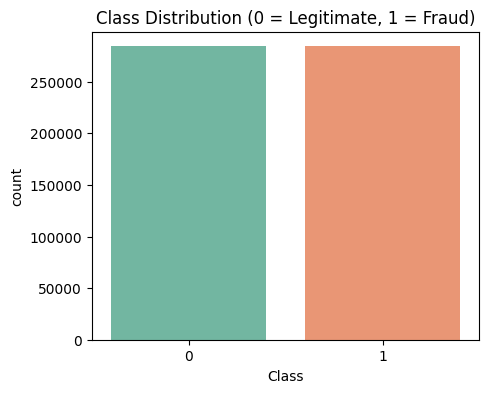

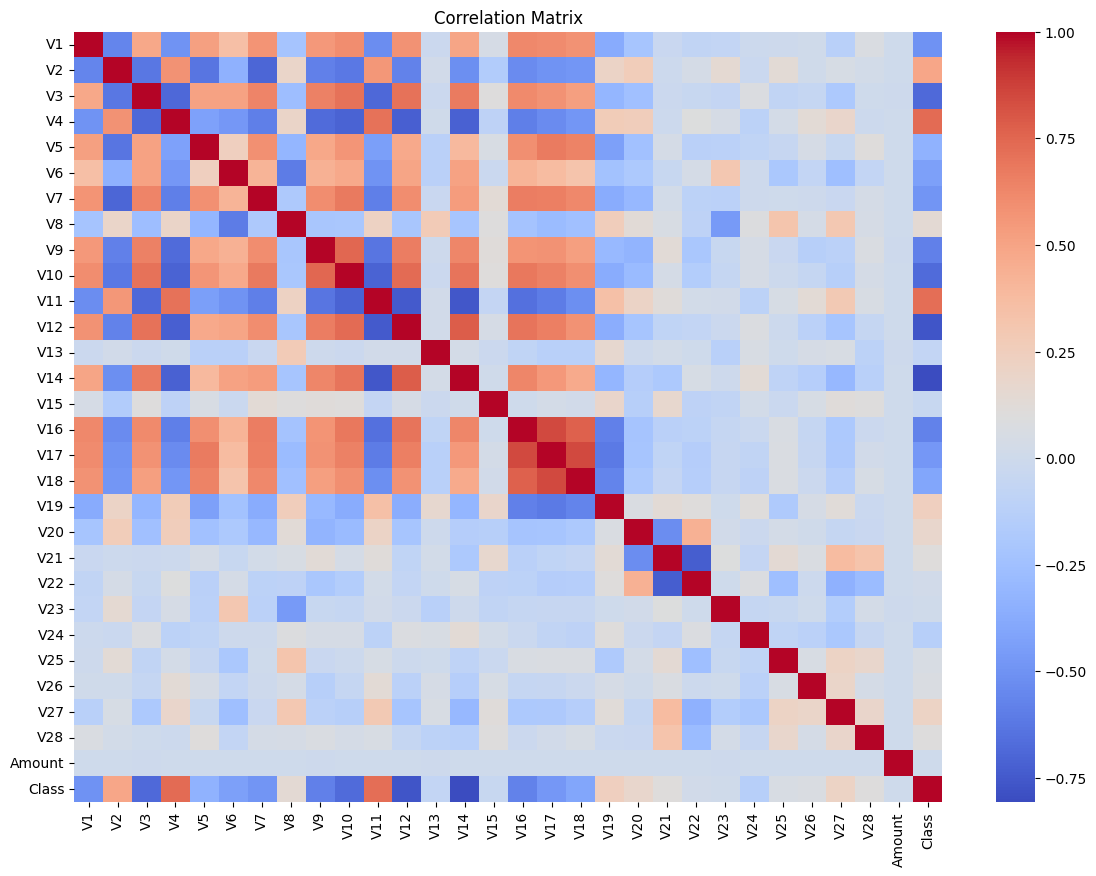

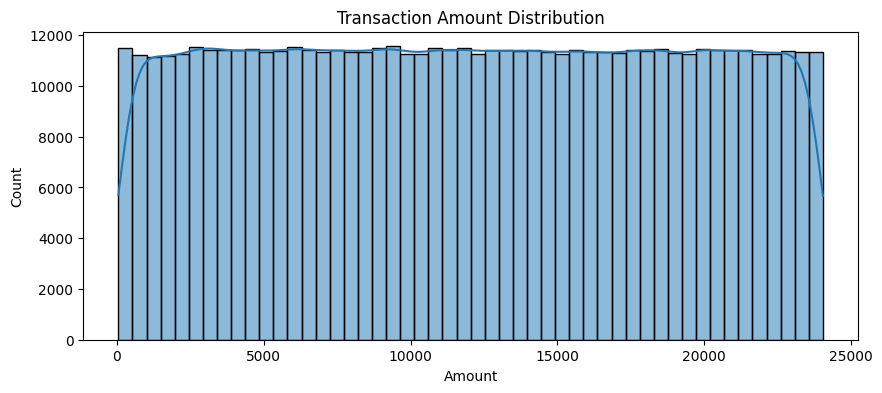

In [5]:
print('\n--- Dataset Info ---')
df.info()

print('\n--- Class Distribution ---')
print(df['Class'].value_counts())
print(f"Fraud ratio: {df['Class'].mean():.4f}")

plt.figure(figsize=(5, 4))
sns.countplot(x='Class', data=df, palette='Set2')
plt.title('Class Distribution (0 = Legitimate, 1 = Fraud)')
plt.show()

plt.figure(figsize=(14, 10))
sns.heatmap(df.drop('id', axis=1).corr(), cmap='coolwarm', annot=False)
plt.title('Correlation Matrix')
plt.show()

plt.figure(figsize=(10, 4))
sns.histplot(df['Amount'], bins=50, kde=True)
plt.title('Transaction Amount Distribution')
plt.show()


In [6]:
X = df.drop(['id', 'Class'], axis=1)
y = df['Class']

scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'\nTraining set: {X_train.shape}, Test set: {X_test.shape}')


Training set: (454904, 29), Test set: (113726, 29)



===== Logistic Regression =====
              precision    recall  f1-score   support

       Legit       0.95      0.98      0.97     56863
       Fraud       0.98      0.95      0.96     56863

    accuracy                           0.96    113726
   macro avg       0.97      0.96      0.96    113726
weighted avg       0.97      0.96      0.96    113726

ROC AUC: 0.9935


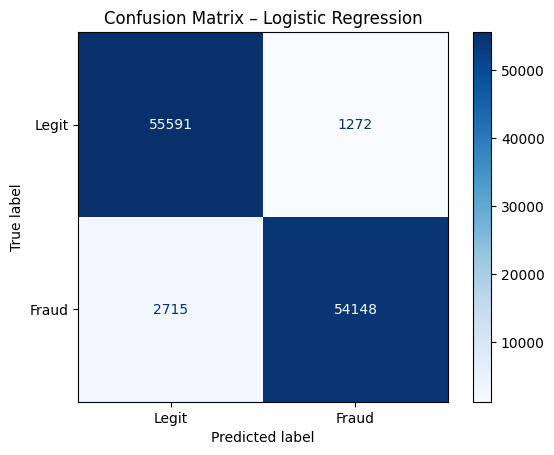


===== Decision Tree =====
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56863
       Fraud       1.00      1.00      1.00     56863

    accuracy                           1.00    113726
   macro avg       1.00      1.00      1.00    113726
weighted avg       1.00      1.00      1.00    113726

ROC AUC: 0.9978


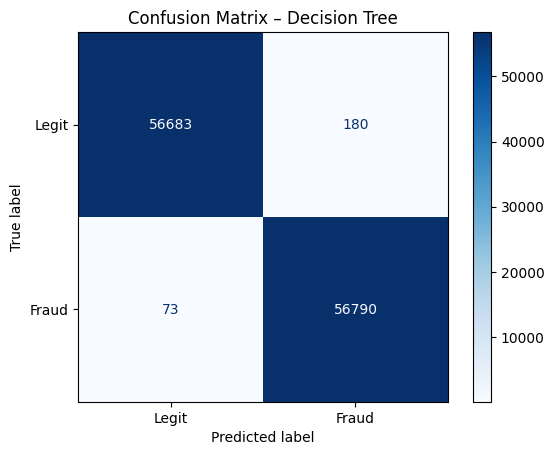


===== Random Forest =====
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     56863
       Fraud       1.00      1.00      1.00     56863

    accuracy                           1.00    113726
   macro avg       1.00      1.00      1.00    113726
weighted avg       1.00      1.00      1.00    113726

ROC AUC: 1.0000


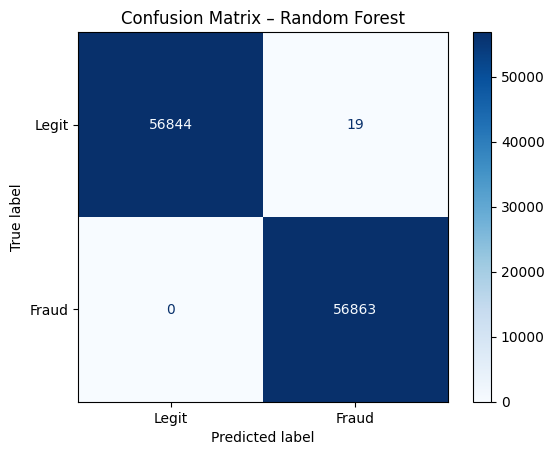

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100,
                                                  random_state=42, n_jobs=-1)
}

results = {}
for name, model in models.items():
    print(f'\n===== {name} =====')
    model.fit(X_train, y_train)
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(classification_report(y_test, y_pred,
                                target_names=['Legit', 'Fraud']))
    print(f'ROC AUC: {roc_auc_score(y_test, y_proba):.4f}')

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=['Legit', 'Fraud'], cmap='Blues'
    )
    plt.title(f'Confusion Matrix – {name}')
    plt.show()

    results[name] = {
        'accuracy': model.score(X_test, y_test),
        'roc_auc':  roc_auc_score(y_test, y_proba)
    }

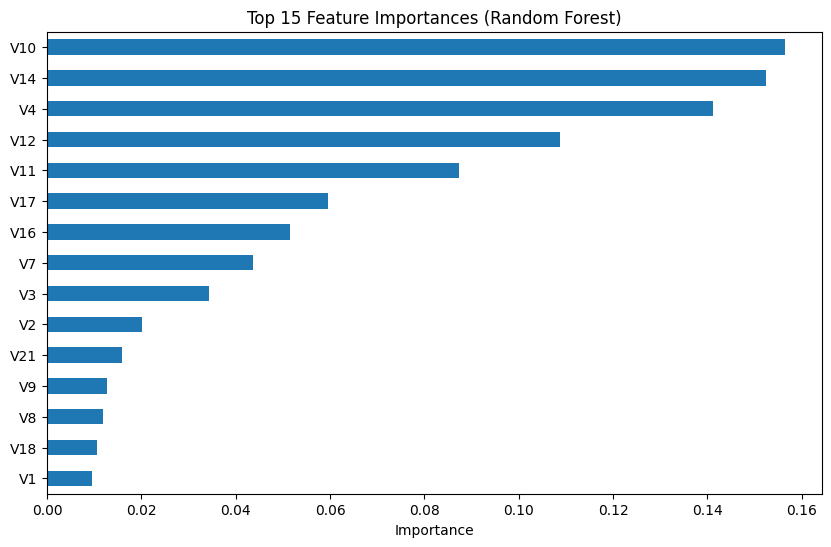

In [8]:
rf = models['Random Forest']
importances = pd.Series(rf.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top_features.plot(kind='barh')
plt.gca().invert_yaxis()
plt.title('Top 15 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.show()

In [9]:
print('\n=== Summary of Results ===')
for name, m in results.items():
    print(f'{name}: Accuracy = {m["accuracy"]:.4f}, '
          f'ROC AUC = {m["roc_auc"]:.4f}')


=== Summary of Results ===
Logistic Regression: Accuracy = 0.9649, ROC AUC = 0.9935
Decision Tree: Accuracy = 0.9978, ROC AUC = 0.9978
Random Forest: Accuracy = 0.9998, ROC AUC = 1.0000
